# Blue Economy Time Series Forecasting: RNN vs LSTM vs GRU
### Indian Ocean Tuna Commission (IOTC) Catch Data — WPTT28

This notebook compares **RNN, LSTM, and GRU** architectures for forecasting monthly tropical tuna catch
(Yellowfin, Bigeye, Skipjack) in the Indian Ocean, using official IOTC catch-and-effort data.

**Run this in Google Colab** (Runtime → Change runtime type → GPU) for TensorFlow/Keras support.

Upload `monthly_total_catch.csv` and `monthly_species_catch.csv` to the Colab session (or your Drive) before running.


In [ ]:
%pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement tensorflow (from versions: none)

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for tensorflow


## 1. Setup

In [1]:
%pip install -q tensorflow scikit-learn pandas matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

tf.random.set_seed(42)
np.random.seed(42)


## 2. Load data
If running in Colab, upload the two CSVs first (files icon on the left → upload), or mount Drive.

In [8]:
#from google.colab import files
 # uploaded = files.upload()  # uncomment to upload interactively

total_df = pd.read_csv("monthly_total_catch.csv", parse_dates=["date"])
species_df = pd.read_csv("monthly_species_catch.csv", parse_dates=["date"])

print(total_df.shape, species_df.shape)
total_df.head()


(708, 4) (708, 6)


,year,month,catch_mt_total,date
0,1967,1,249.96956,1967-01-01
1,1967,2,254.50284,1967-02-01
2,1967,3,232.97904,1967-03-01
3,1967,4,148.45100,1967-04-01
4,1967,5,159.86308,1967-05-01


## 3. Exploratory look at the series

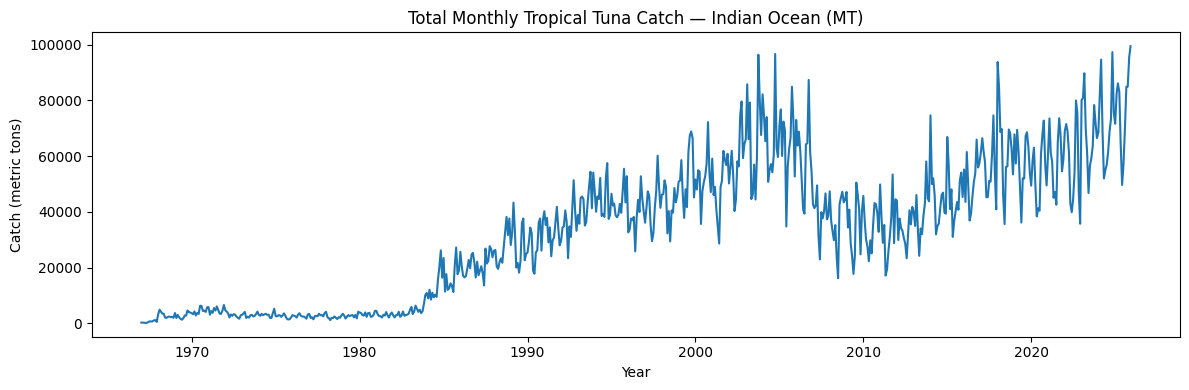

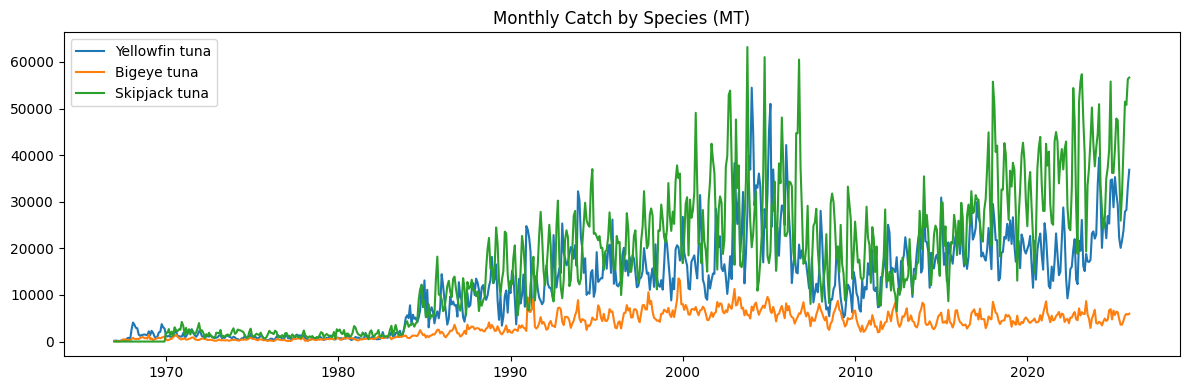

In [9]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(total_df["date"], total_df["catch_mt_total"])
ax.set_title("Total Monthly Tropical Tuna Catch — Indian Ocean (MT)")
ax.set_xlabel("Year"); ax.set_ylabel("Catch (metric tons)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12,4))
for col in ["Yellowfin tuna","Bigeye tuna","Skipjack tuna"]:
    ax.plot(species_df["date"], species_df[col], label=col)
ax.set_title("Monthly Catch by Species (MT)")
ax.legend(); plt.tight_layout(); plt.show()


## 4. Preprocessing
We forecast **total monthly catch**. Scale to [0,1] and build sliding windows (12-month lookback → predict next month).

In [10]:
series = total_df["catch_mt_total"].values.reshape(-1,1)

# chronological split: 70% train, 15% val, 15% test
n = len(series)
train_end = int(n*0.70)
val_end = int(n*0.85)

scaler = MinMaxScaler()
scaler.fit(series[:train_end])  # fit ONLY on train to avoid leakage
series_scaled = scaler.transform(series)

LOOKBACK = 12  # months

def make_windows(data, lookback):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i:i+lookback, 0])
        y.append(data[i+lookback, 0])
    return np.array(X), np.array(y)

X_all, y_all = make_windows(series_scaled, LOOKBACK)

# align split indices (shifted by lookback)
train_end_w = train_end - LOOKBACK
val_end_w = val_end - LOOKBACK

X_train, y_train = X_all[:train_end_w], y_all[:train_end_w]
X_val, y_val = X_all[train_end_w:val_end_w], y_all[train_end_w:val_end_w]
X_test, y_test = X_all[val_end_w:], y_all[val_end_w:]

# reshape for RNN input: (samples, timesteps, features)
X_train = X_train.reshape(-1, LOOKBACK, 1)
X_val = X_val.reshape(-1, LOOKBACK, 1)
X_test = X_test.reshape(-1, LOOKBACK, 1)

print("train:", X_train.shape, "val:", X_val.shape, "test:", X_test.shape)


train: (483, 12, 1) val: (106, 12, 1) test: (107, 12, 1)


## 5. Model builders
Same layer size (32 units) and training setup for all three, so the comparison isolates the *architecture* effect.

In [11]:
def build_model(cell_type, units=32, lookback=LOOKBACK, dropout=0.2):
    layer = {"RNN": SimpleRNN, "LSTM": LSTM, "GRU": GRU}[cell_type]
    model = Sequential([
        layer(units, activation="tanh", input_shape=(lookback, 1)),
        Dropout(dropout),
        Dense(16, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

results = {}
histories = {}
predictions = {}

for cell_type in ["RNN", "LSTM", "GRU"]:
    print(f"\n=== Training {cell_type} ===")
    model = build_model(cell_type)
    es = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    hist = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=200, batch_size=16,
        callbacks=[es], verbose=0
    )
    histories[cell_type] = hist

    y_pred_scaled = model.predict(X_test, verbose=0).flatten()
    y_pred = scaler.inverse_transform(y_pred_scaled.reshape(-1,1)).flatten()
    y_true = scaler.inverse_transform(y_test.reshape(-1,1)).flatten()
    predictions[cell_type] = (y_true, y_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)

    results[cell_type] = {
        "RMSE (MT)": rmse, "MAE (MT)": mae, "MAPE (%)": mape, "R2": r2,
        "epochs_trained": len(hist.history["loss"]),
        "params": model.count_params()
    }
    print(f"{cell_type}: RMSE={rmse:,.0f}  MAE={mae:,.0f}  MAPE={mape:.2f}%  R2={r2:.3f}")



=== Training RNN ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


RNN: RMSE=11,122  MAE=8,443  MAPE=12.95%  R2=0.414

=== Training LSTM ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LSTM: RMSE=11,168  MAE=8,802  MAPE=14.35%  R2=0.410

=== Training GRU ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


GRU: RMSE=10,189  MAE=7,764  MAPE=12.81%  R2=0.509


## 6. Comparison table

In [12]:
results_df = pd.DataFrame(results).T
results_df = results_df[["RMSE (MT)","MAE (MT)","MAPE (%)","R2","epochs_trained","params"]]
results_df


,RMSE (MT),MAE (MT),MAPE (%),R2,epochs_trained,params
RNN,11121.924177,8442.833528,12.945870,0.414486,45.0,1633.0
LSTM,11167.953949,8801.930402,14.346697,0.409629,157.0,4897.0
GRU,10189.487003,7763.793610,12.810512,0.508547,157.0,3905.0


## 7. Training curves

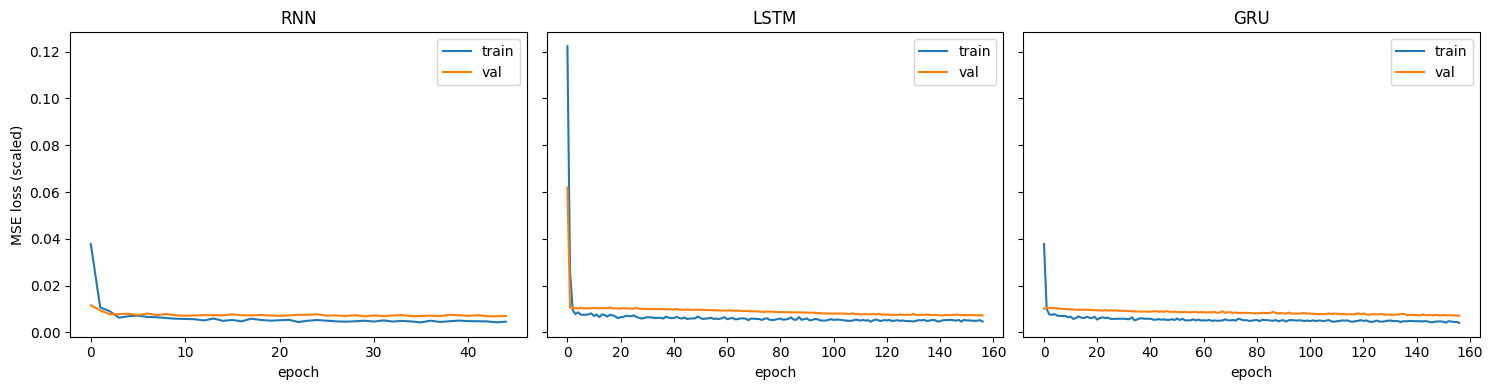

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15,4), sharey=True)
for ax, cell_type in zip(axes, ["RNN","LSTM","GRU"]):
    h = histories[cell_type]
    ax.plot(h.history["loss"], label="train")
    ax.plot(h.history["val_loss"], label="val")
    ax.set_title(cell_type); ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("MSE loss (scaled)")
plt.tight_layout(); plt.show()


## 8. Forecasts vs actuals on the test set

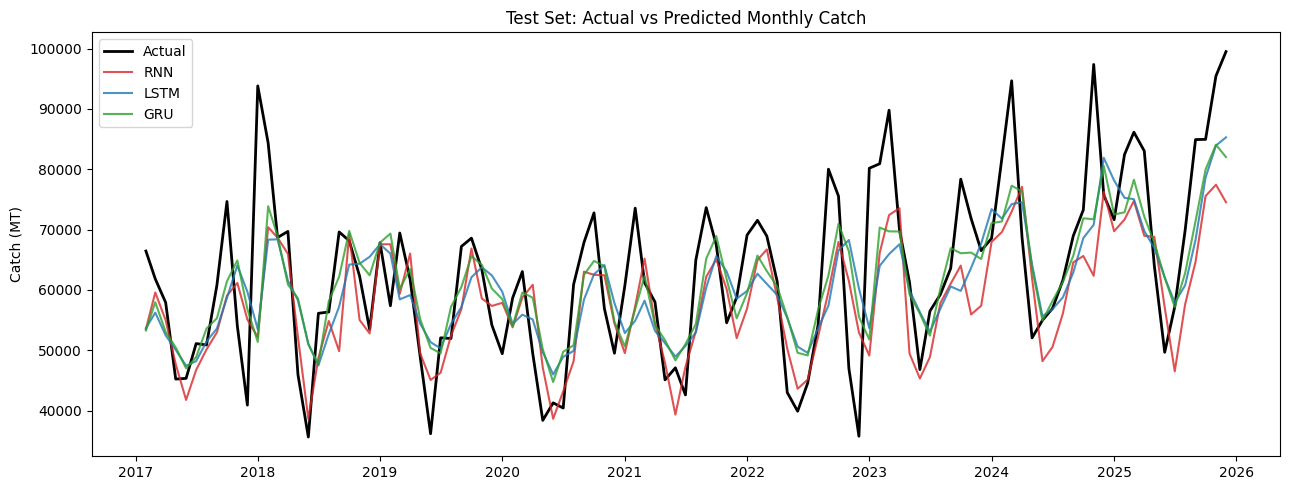

In [14]:
fig, ax = plt.subplots(figsize=(13,5))
test_dates = total_df["date"].values[-len(y_test):]
y_true_ref = predictions["LSTM"][0]
ax.plot(test_dates, y_true_ref, label="Actual", color="black", linewidth=2)
for cell_type, color in zip(["RNN","LSTM","GRU"], ["tab:red","tab:blue","tab:green"]):
    _, y_pred = predictions[cell_type]
    ax.plot(test_dates, y_pred, label=cell_type, color=color, alpha=0.8)
ax.set_title("Test Set: Actual vs Predicted Monthly Catch")
ax.set_ylabel("Catch (MT)"); ax.legend()
plt.tight_layout(); plt.show()


## 13. Discussion

Use the automatic testing results and comparison graphs above to explain which architecture performed best and why.

## 9. Final testing and model evaluation
All models are evaluated on the same unseen **test set**. The metrics below are calculated using the original catch values in metric tons (MT).

In [15]:
# Reusable evaluation function for the final test set
def evaluate_test_predictions(y_true, y_pred):
    # Avoid division-by-zero problems in MAPE
    nonzero = np.abs(y_true) > 1e-8
    mape = np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])) * 100

    errors = y_true - y_pred

    return {
        "RMSE (MT)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE (MT)": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": mape,
        "R2": r2_score(y_true, y_pred),
        "Bias (MT)": np.mean(errors),
        "Max Error (MT)": np.max(np.abs(errors))
    }

# Independent test-set metrics for every model
test_results = {}
for model_name, (y_true, y_pred) in predictions.items():
    test_results[model_name] = evaluate_test_predictions(y_true, y_pred)

test_results_df = pd.DataFrame(test_results).T
test_results_df = test_results_df.sort_values("RMSE (MT)")
test_results_df.round(3)


,RMSE (MT),MAE (MT),MAPE (%),R2,Bias (MT),Max Error (MT)
GRU,10189.487,7763.794,12.811,0.509,1529.078,42436.627
RNN,11121.924,8442.834,12.946,0.414,4733.557,41638.584
LSTM,11167.954,8801.930,14.347,0.410,2528.812,40345.959


## 10. Metrics comparison and model ranking
Lower **RMSE, MAE, MAPE, and Max Error** values are better. Higher **R²** is better.

In [16]:
# Add ranks for easier model comparison
ranking_df = test_results_df.copy()
ranking_df["RMSE Rank"] = ranking_df["RMSE (MT)"].rank(method="min", ascending=True).astype(int)
ranking_df["MAE Rank"] = ranking_df["MAE (MT)"].rank(method="min", ascending=True).astype(int)
ranking_df["MAPE Rank"] = ranking_df["MAPE (%)"].rank(method="min", ascending=True).astype(int)
ranking_df["R2 Rank"] = ranking_df["R2"].rank(method="min", ascending=False).astype(int)
ranking_df["Average Rank"] = ranking_df[["RMSE Rank", "MAE Rank", "MAPE Rank", "R2 Rank"]].mean(axis=1)

ranking_df = ranking_df.sort_values("Average Rank")
print("MODEL RANKING (1 = BEST)")
display(ranking_df.round(3))


MODEL RANKING (1 = BEST)


,RMSE (MT),MAE (MT),MAPE (%),R2,Bias (MT),Max Error (MT),RMSE Rank,MAE Rank,MAPE Rank,R2 Rank,Average Rank
GRU,10189.487,7763.794,12.811,0.509,1529.078,42436.627,1,1,1,1,1.0
RNN,11121.924,8442.834,12.946,0.414,4733.557,41638.584,2,2,2,2,2.0
LSTM,11167.954,8801.930,14.347,0.410,2528.812,40345.959,3,3,3,3,3.0


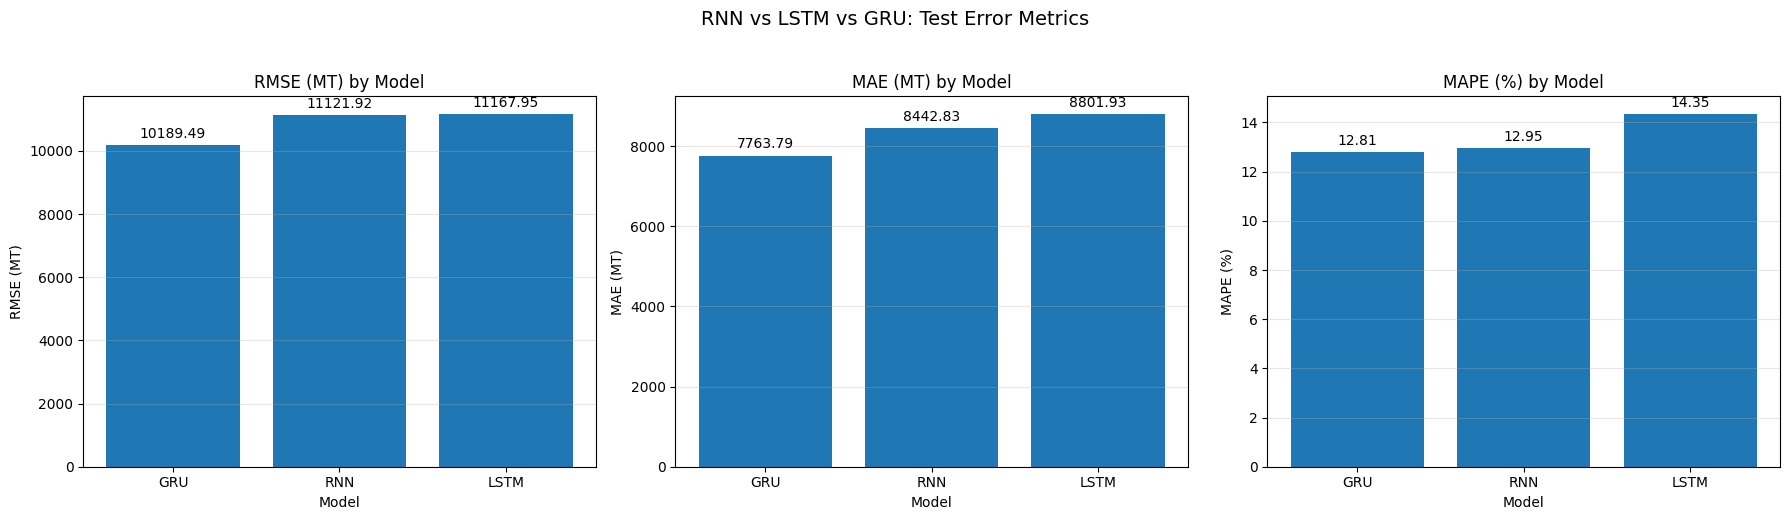

In [17]:
# Graph 1: Error metrics comparison
error_metrics = ["RMSE (MT)", "MAE (MT)", "MAPE (%)"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric in zip(axes, error_metrics):
    values = test_results_df[metric].sort_values(ascending=True)
    bars = ax.bar(values.index, values.values)
    ax.set_title(f"{metric} by Model")
    ax.set_xlabel("Model")
    ax.set_ylabel(metric)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("RNN vs LSTM vs GRU: Test Error Metrics", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()


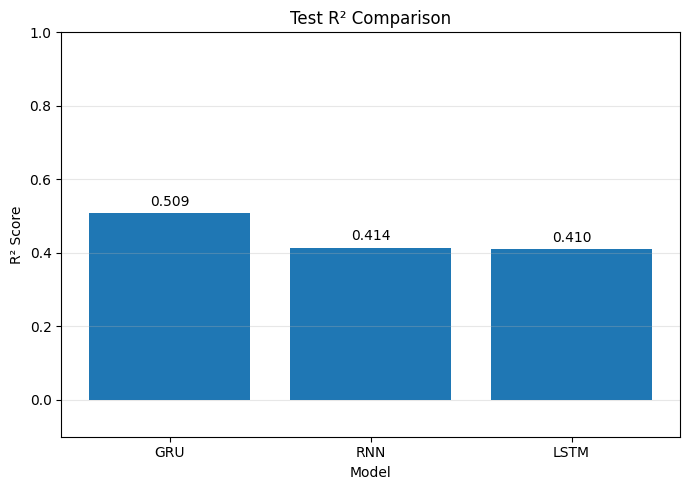

In [18]:
# Graph 2: R² comparison (higher is better)
r2_values = test_results_df["R2"].sort_values(ascending=False)

plt.figure(figsize=(7, 5))
bars = plt.bar(r2_values.index, r2_values.values)
plt.title("Test R² Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.ylim(min(-0.1, r2_values.min() - 0.05), 1.0)
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Testing visualization: prediction errors
Residuals show whether each model consistently over-predicts or under-predicts. A good model should have errors distributed around zero.

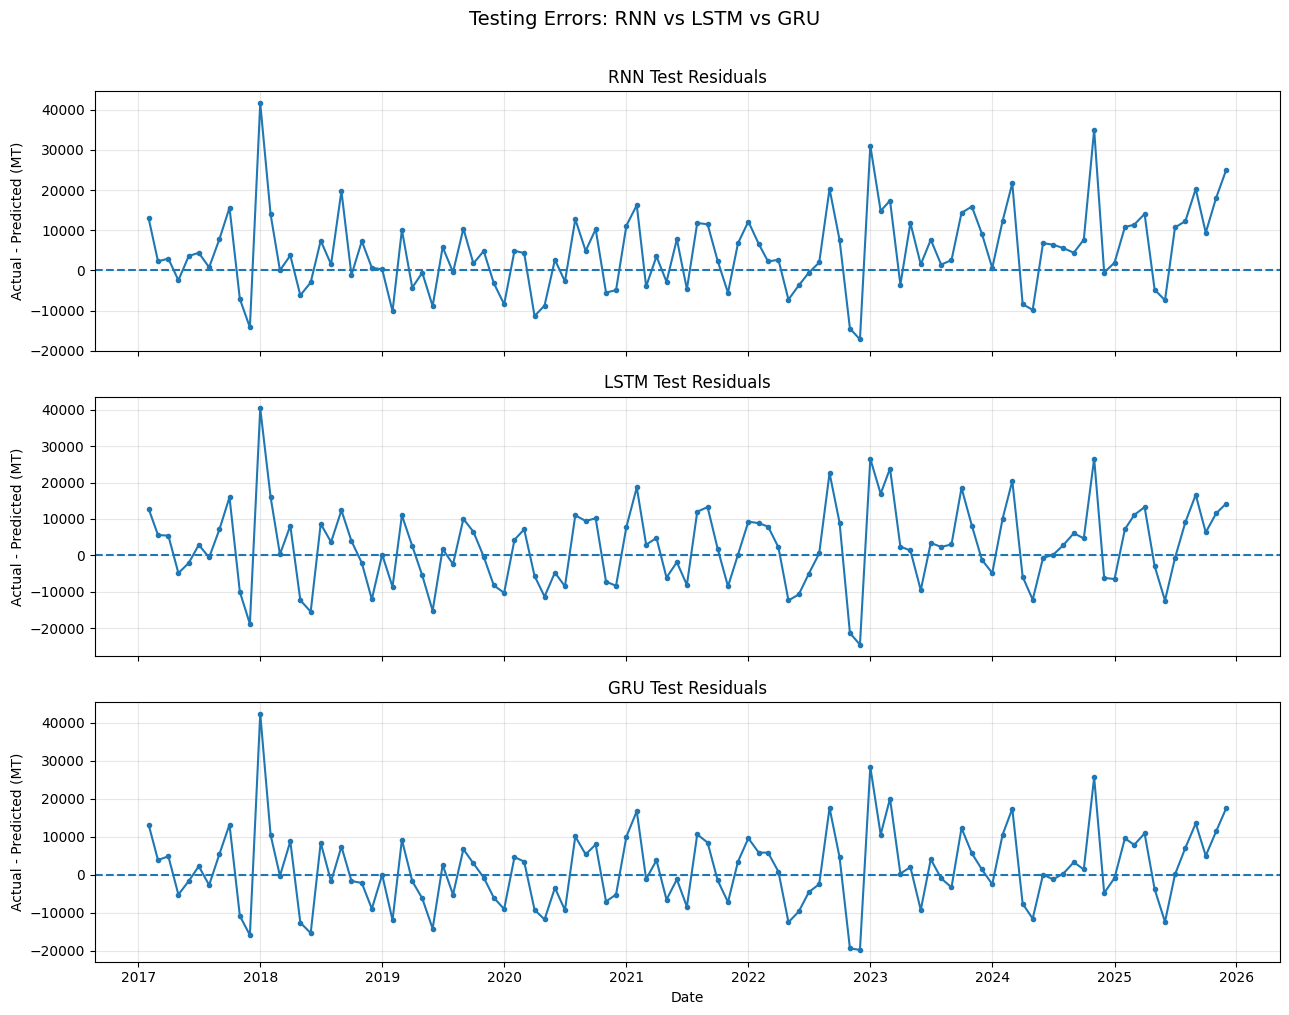

In [19]:
# Graph 3: Residual/error comparison on the test set
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

for ax, model_name in zip(axes, ["RNN", "LSTM", "GRU"]):
    y_true, y_pred = predictions[model_name]
    residuals = y_true - y_pred

    ax.plot(test_dates, residuals, marker="o", markersize=3)
    ax.axhline(0, linestyle="--")
    ax.set_title(f"{model_name} Test Residuals")
    ax.set_ylabel("Actual - Predicted (MT)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
plt.suptitle("Testing Errors: RNN vs LSTM vs GRU", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


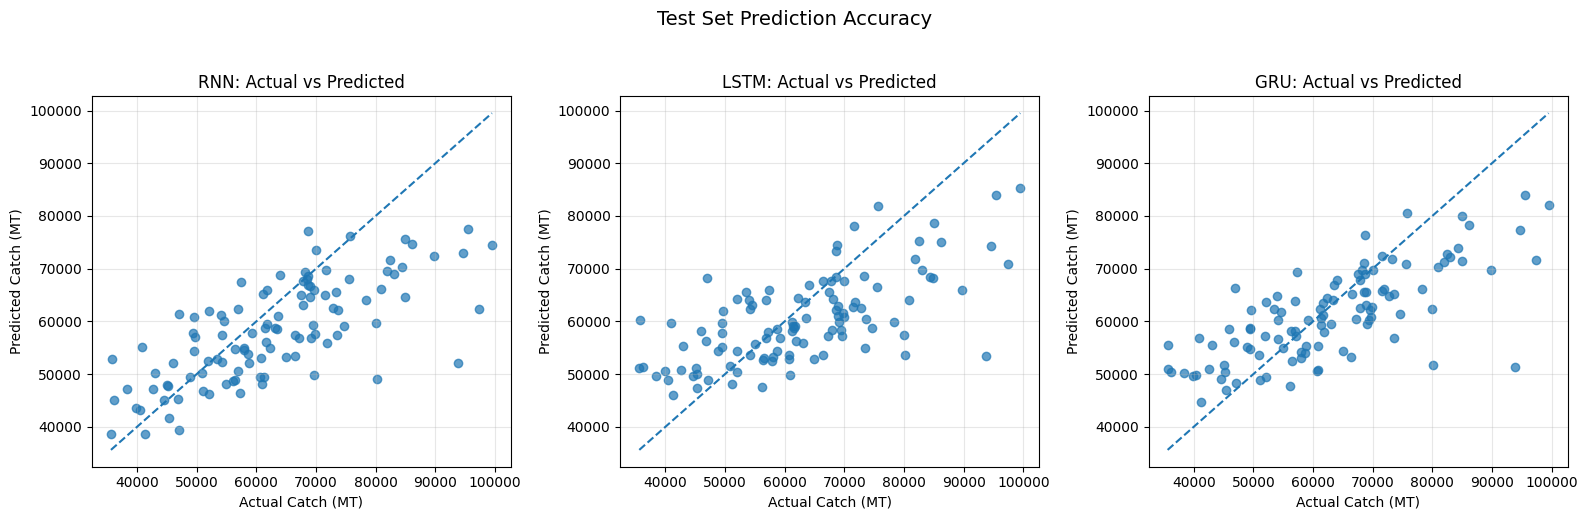

In [20]:
# Graph 4: Actual vs predicted scatter plot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, model_name in zip(axes, ["RNN", "LSTM", "GRU"]):
    y_true, y_pred = predictions[model_name]

    ax.scatter(y_true, y_pred, alpha=0.7)
    low = min(y_true.min(), y_pred.min())
    high = max(y_true.max(), y_pred.max())
    ax.plot([low, high], [low, high], linestyle="--")

    ax.set_title(f"{model_name}: Actual vs Predicted")
    ax.set_xlabel("Actual Catch (MT)")
    ax.set_ylabel("Predicted Catch (MT)")
    ax.grid(alpha=0.3)

plt.suptitle("Test Set Prediction Accuracy", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()


## 12. Automatic conclusion from the test results

In [21]:
best_rmse_model = test_results_df["RMSE (MT)"].idxmin()
best_mae_model = test_results_df["MAE (MT)"].idxmin()
best_mape_model = test_results_df["MAPE (%)"].idxmin()
best_r2_model = test_results_df["R2"].idxmax()
overall_best = ranking_df.index[0]

print("FINAL TESTING CONCLUSION")
print("-" * 50)
print(f"Best RMSE model : {best_rmse_model} ({test_results_df.loc[best_rmse_model, 'RMSE (MT)']:,.2f} MT)")
print(f"Best MAE model  : {best_mae_model} ({test_results_df.loc[best_mae_model, 'MAE (MT)']:,.2f} MT)")
print(f"Best MAPE model : {best_mape_model} ({test_results_df.loc[best_mape_model, 'MAPE (%)']:.2f}%)")
print(f"Best R² model   : {best_r2_model} ({test_results_df.loc[best_r2_model, 'R2']:.3f})")
print("-" * 50)
print(f"Overall best model based on average metric rank: {overall_best}")


FINAL TESTING CONCLUSION
--------------------------------------------------
Best RMSE model : GRU (10,189.49 MT)
Best MAE model  : GRU (7,763.79 MT)
Best MAPE model : GRU (12.81%)
Best R² model   : GRU (0.509)
--------------------------------------------------
Overall best model based on average metric rank: GRU
